In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math

# Two temperatures, ordered and unordered

In [55]:
def process_df(df):
    output = pd.DataFrame(columns=['MC_cycles', 'epsilon', 'mean epsilon'])

    output['MC_cycles'] = df.index.to_list()
    output['MC_cycles'] +=1

    output['epsilon'] = df['epsilon']

    eps_values = df['epsilon'].to_numpy()
    means = np.zeros(len(eps_values))
    for i in range(10):
        means[i] = np.mean(eps_values[0:i+1])
    output['mean epsilon'] = means

    return output


In [57]:
data = pd.read_csv(f'../Outputs/L20_T1.000000_NOTordered_n10e5.txt')
eps_T10_u = process_df(data)
data = pd.read_csv(f'../Outputs/L20_T1.000000_ordered_n10e5.txt')
eps_T10_o = process_df(data)
data = pd.read_csv(f'../Outputs/L20_T2.400000_NOTordered_n10e5.txt')
eps_T24_u = process_df(data)
data = pd.read_csv(f'../Outputs/L20_T2.400000_ordered_n10e5.txt')
eps_T24_o = process_df(data)

In [63]:
#Analytical for comparison
Lattice_factor = 1/400 #1/N
analytical = -Lattice_factor*(8*math.sinh(8))/(math.cosh(8)+3)

Text(0.5, 1.0, 'Energy per spin as function of MC cycles')

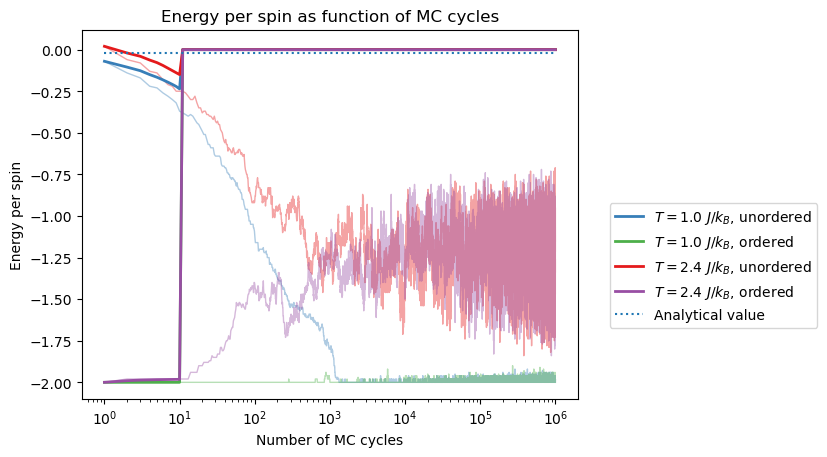

In [64]:
#Snippet from Project description 
plt.plot(eps_T10_u['MC_cycles'], eps_T10_u['epsilon'], '-', color='#377eb8', alpha=0.4, linewidth=1.0)
plt.plot(eps_T10_o['MC_cycles'], eps_T10_o['epsilon'], '-', color='#4daf4a', alpha=0.4, linewidth=1.0)
plt.plot(eps_T24_u['MC_cycles'], eps_T24_u['epsilon'], '-', color='#e41a1c', alpha=0.4, linewidth=1.0)
plt.plot(eps_T24_o['MC_cycles'], eps_T24_o['epsilon'], '-', color='#984ea3', alpha=0.4, linewidth=1.0)
plt.plot(eps_T10_u['MC_cycles'], eps_T10_u['mean epsilon'], '-', linewidth=2.0, color='#377eb8', label='$T=1.0$ $J/k_{B}$, unordered')
plt.plot(eps_T10_o['MC_cycles'], eps_T10_o['mean epsilon'], '-', linewidth=2.0, color='#4daf4a', label='$T=1.0$ $J/k_{B}$, ordered')
plt.plot(eps_T24_u['MC_cycles'], eps_T24_u['mean epsilon'], '-', linewidth=2.0, color='#e41a1c', label='$T=2.4$ $J/k_{B}$, unordered')
plt.plot(eps_T24_o['MC_cycles'], eps_T24_o['mean epsilon'], '-', linewidth=2.0, color='#984ea3', label='$T=2.4$ $J/k_{B}$, ordered')
#################

plt.hlines(analytical, 1, 1000000, linestyles=':', label='Analytical value')
plt.xscale('log')
plt.legend(loc='upper left', bbox_to_anchor=(1.05, 0.55))
plt.xlabel('Number of MC cycles')
plt.ylabel('Energy per spin')
plt.title('Energy per spin as function of MC cycles')

In [75]:
print(eps_T10_o['epsilon'].max())

-1.9


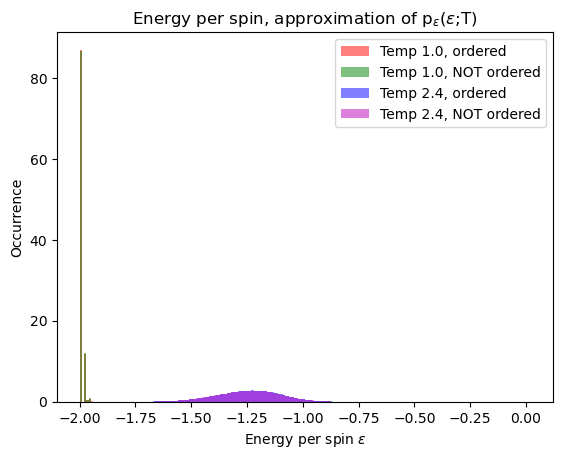

In [93]:
bin_width = 0.01

bins = np.arange(min(eps_T10_o['epsilon']), max(eps_T10_o['epsilon']) + bin_width, bin_width)
plt.hist(eps_T10_o['epsilon'], bins=bins, density=True, alpha=0.5, color='r', label='Temp 1.0, ordered')

bins = np.arange(min(eps_T10_u['epsilon']), max(eps_T10_u['epsilon']) + bin_width, bin_width)
plt.hist(eps_T10_u['epsilon'], bins=bins, density=True, alpha=0.5, color='g', label='Temp 1.0, NOT ordered')

bins = np.arange(min(eps_T24_o['epsilon']), max(eps_T24_o['epsilon']) + bin_width, bin_width)
plt.hist(eps_T24_o['epsilon'], bins=bins, density=True, alpha=0.5, color='b', label='Temp 2.4, ordered')

bins = np.arange(min(eps_T24_u['epsilon']), max(eps_T24_u['epsilon']) + bin_width, bin_width)
plt.hist(eps_T24_u['epsilon'], bins=bins, density=True, alpha=0.5, color='m', label='Temp 2.4, NOT ordered')

plt.title(r'Energy per spin, approximation of p$_{\epsilon}$($\epsilon$;T)')
plt.xlabel(r'Energy per spin $\epsilon$')
plt.ylabel('Occurrence')
plt.legend()

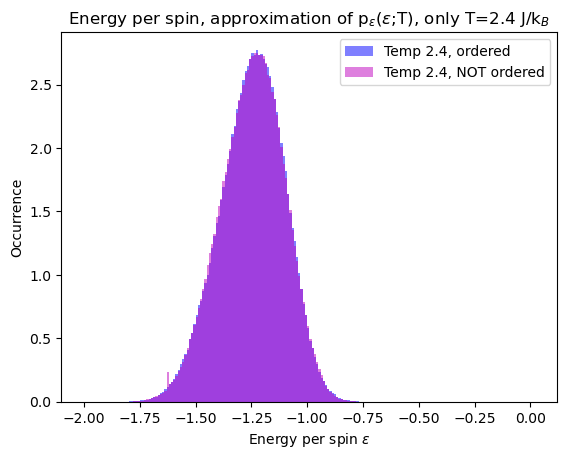

In [94]:
bins = np.arange(min(eps_T24_o['epsilon']), max(eps_T24_o['epsilon']) + bin_width, bin_width)
plt.hist(eps_T24_o['epsilon'], bins=bins, density=True, alpha=0.5, color='b', label='Temp 2.4, ordered')

bins = np.arange(min(eps_T24_u['epsilon']), max(eps_T24_u['epsilon']) + bin_width, bin_width)
plt.hist(eps_T24_u['epsilon'], bins=bins, density=True, alpha=0.5, color='m', label='Temp 2.4, NOT ordered')

plt.title(r'Energy per spin, approximation of p$_{\epsilon}$($\epsilon$;T), only T=2.4 J/k$_B$')
plt.xlabel(r'Energy per spin $\epsilon$')
plt.ylabel('Occurrence')
plt.legend()